# Near-duplicate image detection: notebook

This notebook is the code appendix of the report.
It runs the whole pipeline on Caltech-101, which downloads in about a minute, and documents the commands behind every DISC21 number in the report.
DISC21 images are never bundled: their licence forbids redistribution, so the DISC21 commands download them from Meta's servers.

All code lives in the `near_duplicates` package (`src/near_duplicates/`); the notebook calls its command-line entry points and shows their outputs.

**Setup.** Install [uv](https://docs.astral.sh/uv/), then from the repository root:

```sh
uv sync
uv run jupyter lab notebook.ipynb   # or open it in VS Code with the project's .venv kernel
```

Outline:

1. Data: download Caltech-101 and its fixed splits.
2. The two representations on one image: pHash (the technique from outside the course) and SIFT visual words.
3. LSH: the s-curves of the frozen settings.
4. The experiment on Caltech-101: four systems, 52 transformation conditions, exhaustive search against LSH.
5. Analyses that need no new search: LSH loss against the s-curve prediction, and the cascade.
6. Deduplication by graph clustering.
7. The DISC21 commands behind the report.

In [1]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

RESULTS = Path("results")
SETTINGS = "--vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10".split()  # frozen on DISC21 validation, see docs/findings.md


def cli(module, *args):
    """Run one of the package's commands in this kernel's Python and print its output."""
    completed = subprocess.run([sys.executable, "-m", f"near_duplicates.{module}", *map(str, args)],
                               capture_output=True, text=True)
    print(completed.stdout[-6000:])
    if completed.returncode:
        raise RuntimeError(completed.stderr[-3000:])

## 1. Data

The download script fetches Caltech-101 from CaltechDATA and writes the fixed, seeded splits to `splits/caltech101/` (already committed, so it only re-creates them if missing).
`Faces_easy` is excluded because it holds crops of the `Faces` images, which would be unlabelled near-duplicates.

In [2]:
cli("download", "caltech101")
from near_duplicates.datasets import image_path, load_split

splits = {name: load_split("caltech101", name) for name in ("index", "val_targets", "val_distractors", "test_targets", "test_distractors")}
pd.Series({name: len(ids) for name, ids in splits.items()}, name="images")

caltech101 ready



index               6209
val_targets          500
val_distractors      500
test_targets        2000
test_distractors    2000
Name: images, dtype: int64

## 2. Two representations of one image

pHash reduces the image to 64 bits: grayscale, 32x32, a 2-D DCT, and the sign of the 8x8 lowest frequencies against their median.
Global edits that keep the low frequencies (compression, scaling, blur) barely change it; edits that move content (crop, rotation, flip) change it completely.
SIFT keypoints describe local patches, which survive moving content but not losing detail; each descriptor is mapped to its nearest of k visual words (k-means), and an image becomes a set of words.

In [3]:
from near_duplicates.features import load_image, phash, sift_features
from near_duplicates.lsh import hamming
from near_duplicates.transforms import transform

source = load_image(image_path("caltech101", splits["val_targets"][0]))
rows = []
for kind, strength in [("jpeg", 10), ("downscale", 0.25), ("blur", 4), ("crop", 0.5), ("rotate", 10), ("flip", 1)]:
    edited = transform(source, kind, strength, np.random.default_rng(0))
    rows.append(dict(edit=f"{kind} {strength}", hamming_distance=int(hamming(np.array([phash(source)]), phash(edited))[0]),
                     keypoints=len(sift_features(edited)[1])))
pd.DataFrame(rows).set_index("edit")  # random pairs of images are about 32 bits apart

,hamming_distance,keypoints
edit,,
jpeg 10,0,300
downscale 0.25,0,67
blur 4,0,62
crop 0.5,28,300
rotate 10,20,300
flip 1,32,301


## 3. LSH s-curves

Both LSH families band a signature: an image pair becomes a candidate if all r rows of at least one of b bands agree, with probability 1 - (1 - s^r)^b for per-row agreement s.
For MinHash s is the Jaccard similarity of the word sets; for bit sampling on pHash it is the share of agreeing bits (the code computes the exact curve for sampling without replacement).

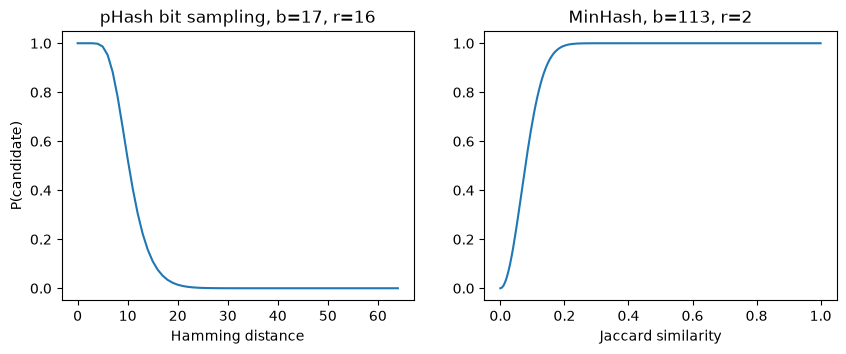

In [4]:
import matplotlib.pyplot as plt
from near_duplicates.lsh import bit_sampling_curve, s_curve

flag = lambda name: int(SETTINGS[SETTINGS.index(name) + 1])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
d = np.arange(65)
left.plot(d, bit_sampling_curve(d, flag("--bit-bands"), flag("--bit-rows")))
left.set(xlabel="Hamming distance", ylabel="P(candidate)", title=f"pHash bit sampling, b={flag('--bit-bands')}, r={flag('--bit-rows')}")
s = np.linspace(0, 1, 201)
right.plot(s, s_curve(s, flag("--minhash-bands"), flag("--minhash-rows")))
right.set(xlabel="Jaccard similarity", title=f"MinHash, b={flag('--minhash-bands')}, r={flag('--minhash-rows')}")
plt.show()

## 4. The experiment on Caltech-101

`run` transforms the validation targets (indexed images) and distractors (images outside the index) under all 52 conditions, searches every system exhaustively and through its LSH index, calibrates each system's threshold at a 1% false-match rate on the distractors, and writes one row per query, system and mode.
`--queries 100` keeps the search to a few minutes; the first run also builds the 8,192-word vocabulary for Caltech-101 (about five minutes, then cached).
Drop `--queries` for the full split, which `--split test` needs because it reuses the validation thresholds.

9                     0.99  0.98
                  15.00          0.01  0.00         0.99  0.98                1.00  0.99                     1.00  0.99
                  30.00          0.00  0.00         1.00  1.00                1.00  1.00                     1.00  1.00
                  45.00          0.00  0.00         1.00  1.00                1.00  1.00                     1.00  1.00
blur              1.00           1.00  1.00         1.00  0.95                1.00  0.95                     1.00  0.95
                  2.00           1.00  1.00         0.92  0.54                0.97  0.55                     0.89  0.55
                  4.00           1.00  1.00         0.47  0.17                0.71  0.21                     0.57  0.19
                  8.00           1.00  1.00         0.05  0.03                0.24  0.05                     0.22  0.03
brightness        0.25           0.99  0.95         1.00  0.99                1.00  0.99                     0.99  0.99
       

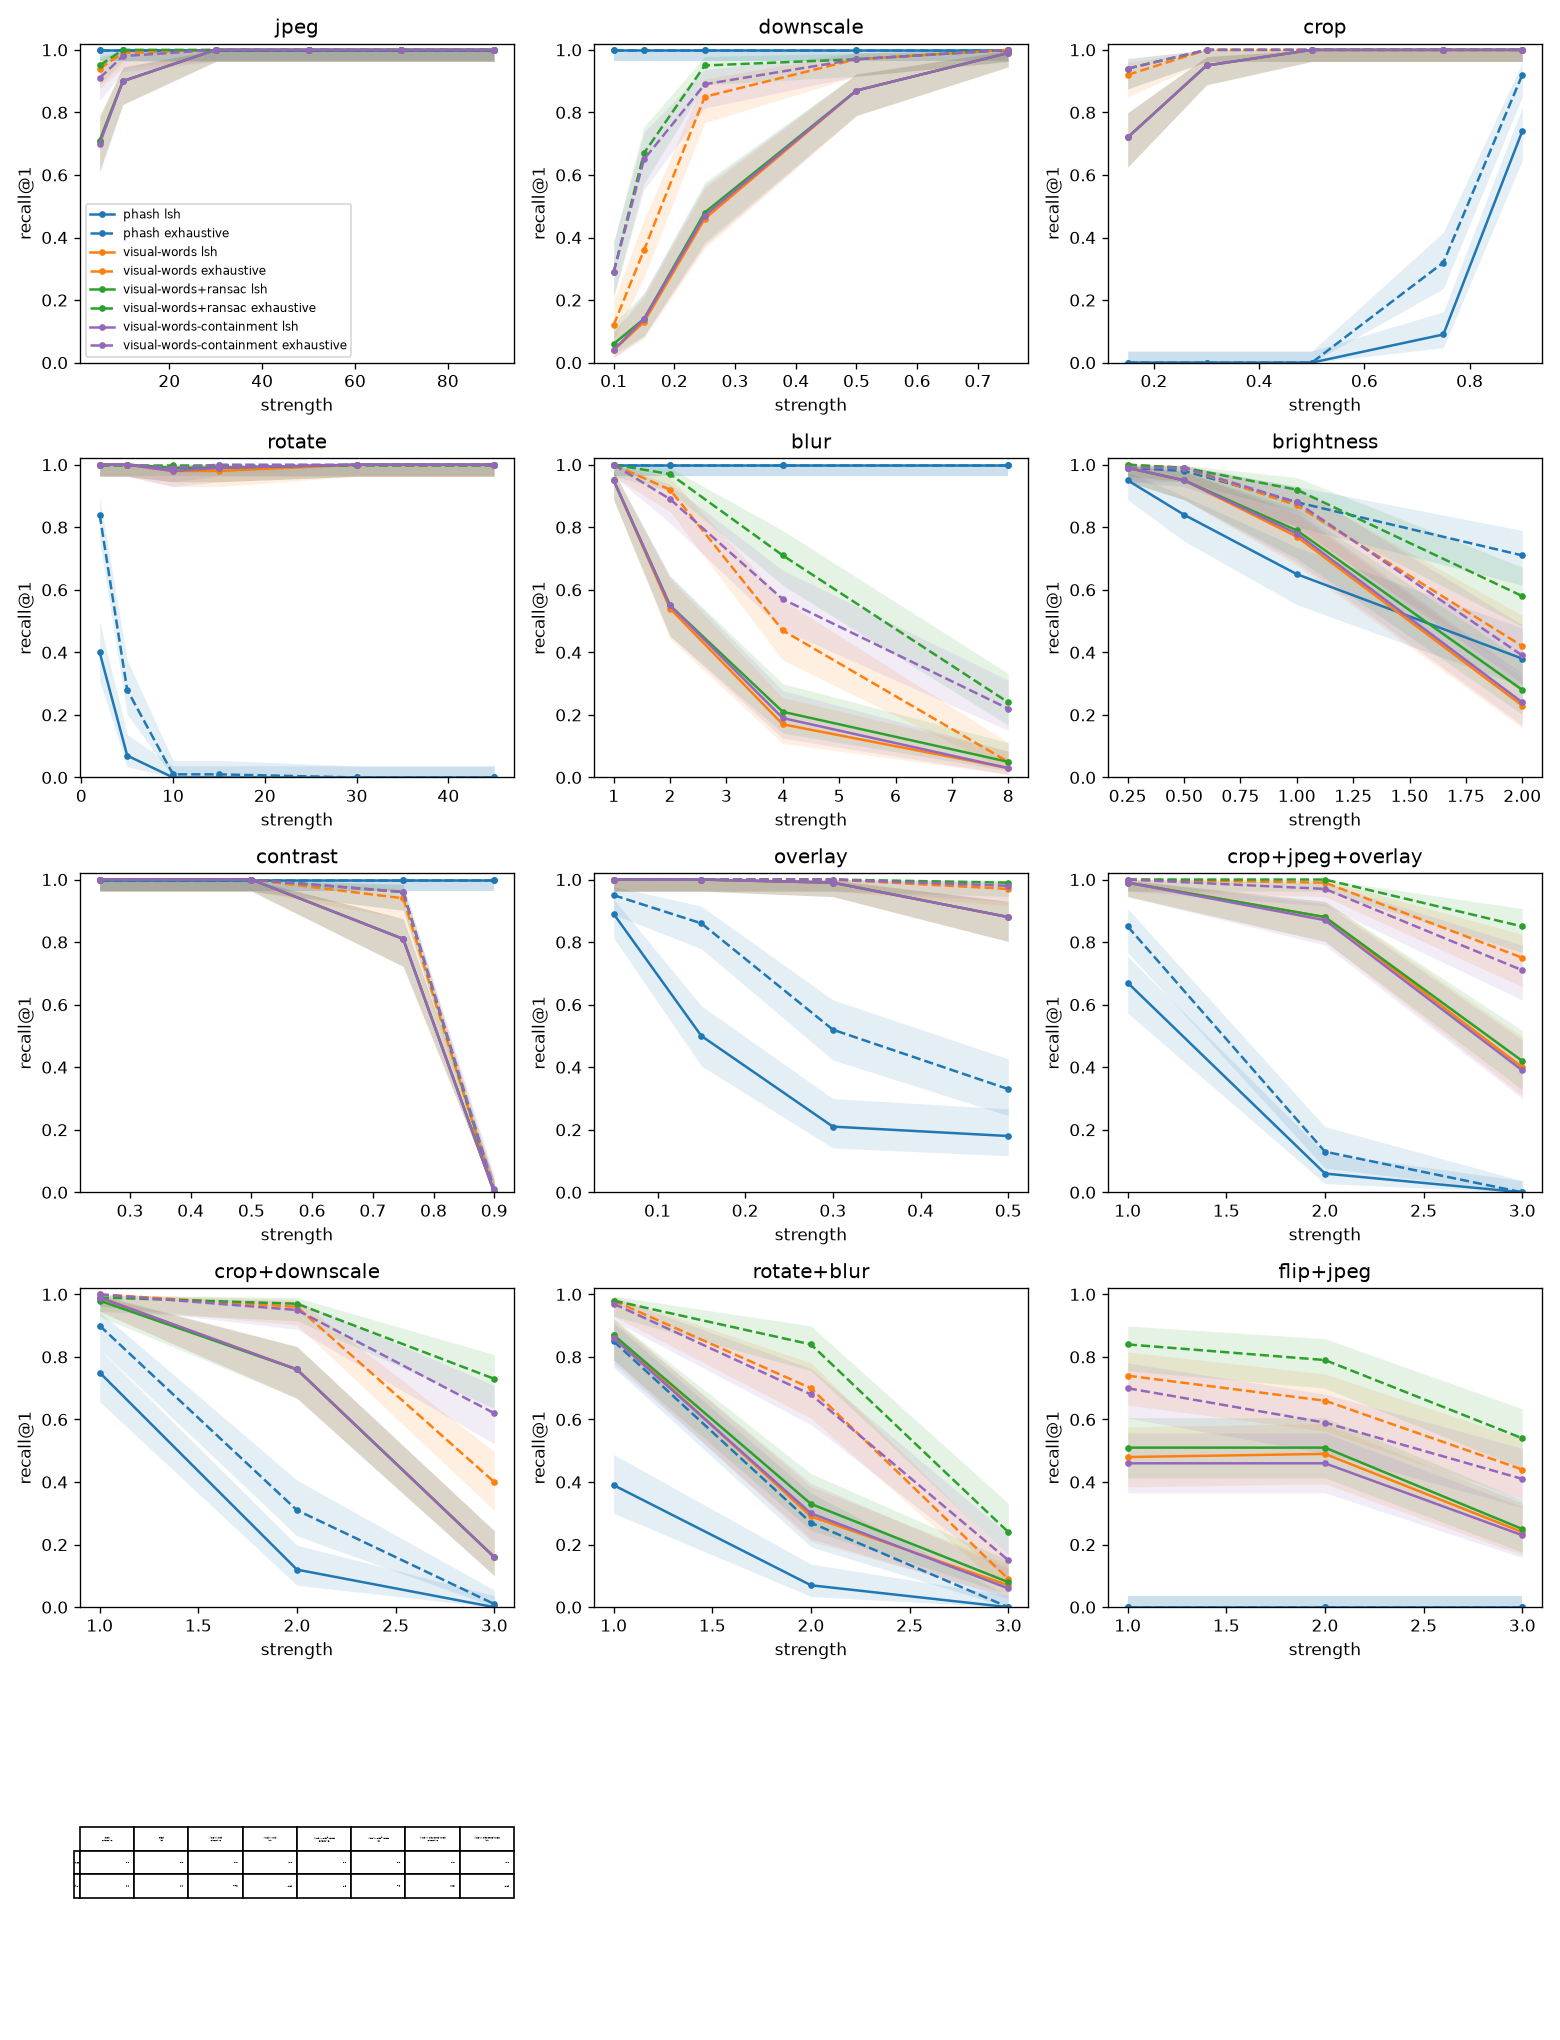

In [5]:
cli("run", "caltech101", "--split", "val", "--queries", "100", *SETTINGS)
tag = sorted(RESULTS.glob("queries_caltech101_*_val_q100.csv"), key=lambda p: p.stat().st_mtime)[-1].stem.removeprefix("queries_")
display(Image(RESULTS / f"recall_{tag}.png"))

## 5. LSH loss and the cascade

`analyze` repeats no search.
It predicts each target's LSH recall from its true similarity through the s-curve and compares it with the measured LSH recall, and it calibrates the cascade (pHash first, visual words only when pHash is not confident) jointly at one false-match rate on half of the source images, reporting on the other half.

         fusion       0.5948      0.5747       0.6158       0.1852    0.1691     0.2008            0.0245   0.0080    0.0468             0.0000  NaN    NaN
                  either       0.6346      0.6118       0.6565       0.2250    0.2133     0.2357            0.0279   0.0106    0.0504             0.0000  NaN    NaN

Recall at the 1% false-match rate, B = visual-words-containment, exhaustive retrieval, held out

method                      phash  visual-words-containment  cascade  fusion  either
kind              strength                                                          
clean             0.00       1.00                      1.00     1.00    1.00    1.00
jpeg              90.00      1.00                      0.47     1.00    1.00    1.00
                  70.00      1.00                      0.00     1.00    1.00    1.00
                  50.00      1.00                      0.00     1.00    1.00    1.00
                  30.00      1.00                      0.00     1.00   

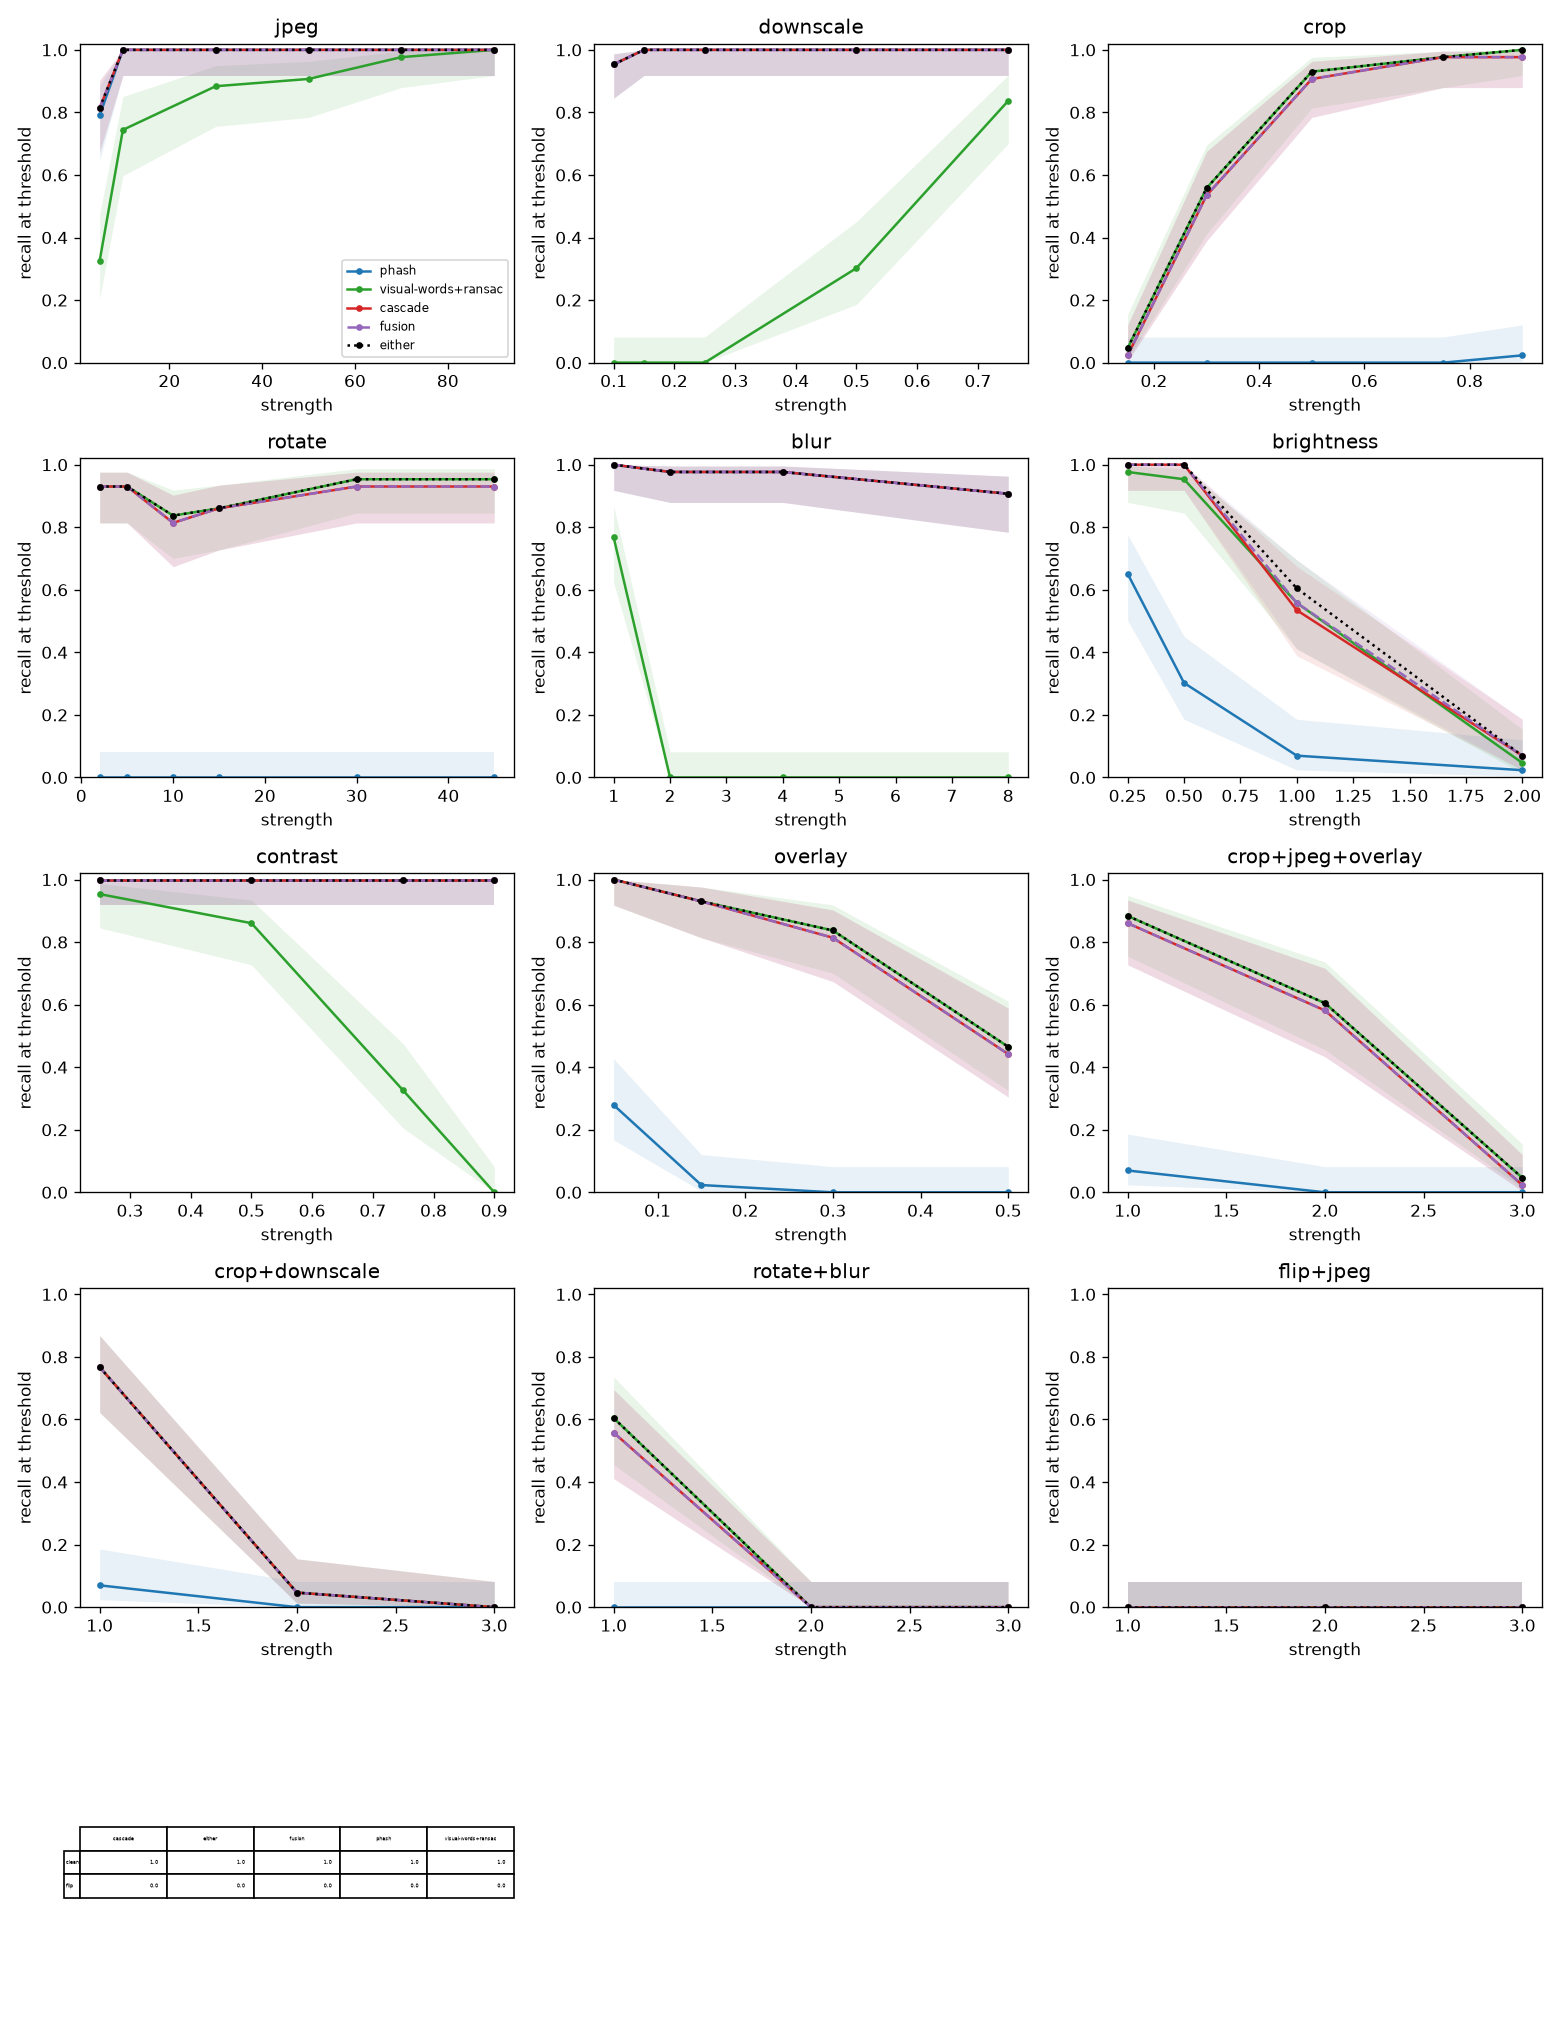

In [6]:
cli("analyze", RESULTS / f"queries_{tag}.csv")
display(Image(RESULTS / f"combinations_{tag}_visual-words+ransac_lsh.png"))

## 6. Deduplication

`dedup` plants transformed copies of random indexed images, joins the catalogue with itself through both LSH indexes, verifies visual-word pairs with RANSAC, and clusters the similarity graph by connected components and by Louvain, scored against the planted groups by the adjusted Rand index and modularity.

In [7]:
cli("dedup", "caltech101", "--groups", "300", "--copies", "3", "--hamming", "8", "10", "--jaccard", "0.3", "0.2",
    "--union", "8:0.3", "--inliers", "20", "25", "--verified-union", "8", *SETTINGS[:SETTINGS.index("--top-k")])
table = pd.read_csv(sorted(RESULTS.glob("dedup_caltech101_*.csv"), key=lambda p: p.stat().st_mtime)[-1])
table.sort_values("ari", ascending=False).head(10)

        system           threshold               method  edges  clusters  largest   ari  pair_precision  pair_recall  modularity
         phash                d<=8 connected components   1482      6320      156 0.083           0.047        0.364       0.857
         phash                d<=8          louvain r=1   1482      6325       91 0.147           0.093        0.364       0.893
         phash                d<=8         louvain r=10   1482      6352       18 0.369           0.374        0.364       0.751
         phash                d<=8        louvain r=100   1482      6433        7 0.460           0.631        0.362       0.626
         phash               d<=10 connected components   2313      6100      239 0.040           0.021        0.398       0.750
         phash               d<=10          louvain r=1   2313      6111      112 0.107           0.062        0.398       0.817
         phash               d<=10         louvain r=10   2313      6153       18 0.317          

,system,threshold,method,edges,clusters,largest,ari,pair_precision,pair_recall,modularity
15,visual-words,J>=0.2,louvain r=100,1104,6354,6,0.791147,0.934191,0.686111,0.972877
23,verified,inliers>=20,louvain r=100,1072,6370,6,0.790655,0.948678,0.677778,0.980780
31,verified,inliers>=25,louvain r=100,1068,6373,6,0.789324,0.951411,0.674444,0.980770
27,union verified,d<=8 or inliers>=20,louvain r=100,2112,6062,7,0.788106,0.760062,0.818333,0.738144
35,union verified,d<=8 or inliers>=25,louvain r=100,2109,6064,7,0.787977,0.761264,0.816667,0.737778
21,verified,inliers>=20,louvain r=1,1072,6365,6,0.786577,0.937020,0.677778,0.995756
20,verified,inliers>=20,connected components,1072,6365,6,0.786577,0.937020,0.677778,0.995756
22,verified,inliers>=20,louvain r=10,1072,6365,6,0.786577,0.937020,0.677778,0.995756
29,verified,inliers>=25,louvain r=1,1068,6368,6,0.785239,0.939628,0.674444,0.995753
30,verified,inliers>=25,louvain r=10,1068,6368,6,0.785239,0.939628,0.674444,0.995753


## 7. DISC21: the commands behind the report

These take hours and about 30 GB of disk, so they are documented rather than run here.
Every number in the report is a test or `dev_report` number; validation runs only chose the settings.

```sh
uv run python -m near_duplicates.download disc21                    # 72,500 images, about 12 GB
uv run python -m near_duplicates.download disc21 --scale 50000      # 50,000 more references for the 100,000-image point
uv run python -m near_duplicates.run disc21 --split val --vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10  # tune; saves the thresholds
uv run python -m near_duplicates.tune results/queries_<tag>_val.csv --vocabulary 512 2048 8192
uv run python -m near_duplicates.run disc21 --split test --vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10 # report
uv run python -m near_duplicates.run disc21 --split test --vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10 --seed 1
uv run python -m near_duplicates.run disc21 --split dev --vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10  # Meta's development queries
uv run python -m near_duplicates.run disc21 --split val --vocabulary 8192 --num-perm 256 --minhash-bands 113 --minhash-rows 2 --bit-bands 17 --bit-rows 16 --top-k 10 --index-size 10000   # and 25000, and --scale for 100,000
uv run python -m near_duplicates.analyze results/queries_<tag>_test.csv
uv run python -m near_duplicates.failures results/queries_<tag>_test.csv
uv run python -m near_duplicates.dedup disc21 --index-size 10000 --seed 1
```